In [110]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Setup Complete")

Setup Complete


In [111]:
df = pd.read_csv("dataset/samplesuperstore.csv")

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,1/3/2023,1/7/2023,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,1/4/2023,1/8/2023,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,1/5/2023,1/12/2023,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [112]:
print(df.columns.tolist())
df.info()
print("Rows and Columns:", df.shape)
df.isnull().sum()
df.describe()


['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          10194 non-null  int64  
 1   Order ID        10194 non-null  object 
 2   Order Date      10194 non-null  object 
 3   Ship Date       10194 non-null  object 
 4   Ship Mode       10194 non-null  object 
 5   Customer ID     10194 non-null  object 
 6   Customer Name   10194 non-null  object 
 7   Segment         10194 non-null  object 
 8   Country/Region  10194 non-null  object 
 9   City            10194 non-null  object 
 10  State/Province  10194 non-null  object 
 11  Postal Code     10194 non

,Row ID,Sales,Quantity,Discount,Profit
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,228.225854,3.791838,0.155385,28.673417
std,2942.898656,619.906839,2.228317,0.206249,232.465115
min,1.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2549.250000,17.220000,2.000000,0.000000,1.760800
50%,5097.500000,53.910000,3.000000,0.200000,8.690000
75%,7645.750000,209.500000,5.000000,0.200000,29.297925
max,10194.000000,22638.480000,14.000000,0.800000,8399.976000


## Dataset Inspection

The dataset was loaded successfully.
No major issues were observed during initial inspection.
The dataset contains retail sales transactions with customer, product, sales and profit information.

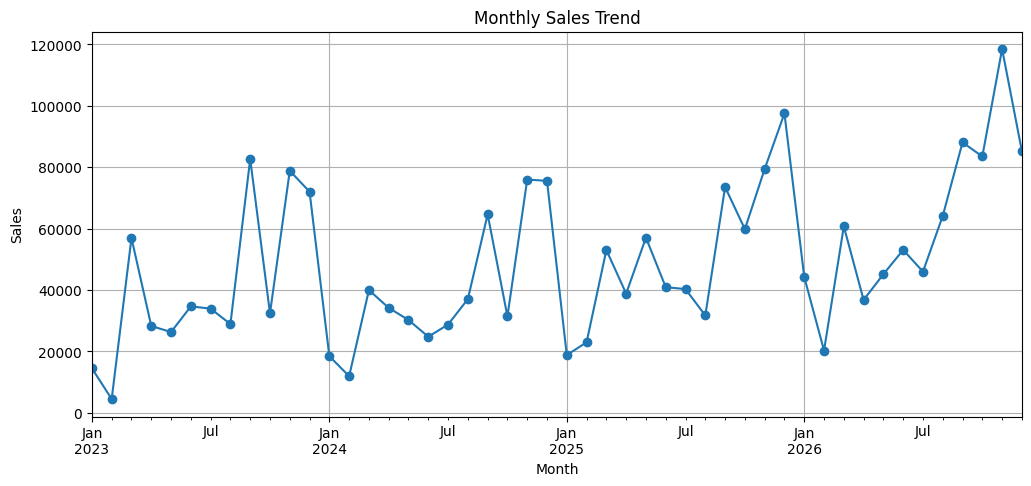

In [113]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
monthly_sales = df.groupby(
    df['Order Date'].dt.to_period('M')
)['Sales'].sum()

monthly_sales.plot(
    figsize=(12,5),
    marker='o'
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.grid(True)
plt.show()

Observation:
Monthly sales fluctuate throughout the year with certain months generating significantly higher revenue than others.

In [114]:
df['Order Date'] = pd.to_datetime(df['Order Date'])

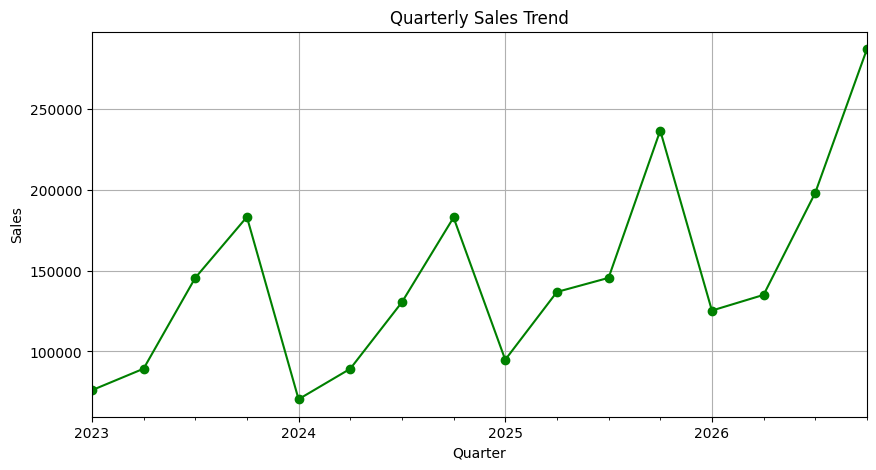

In [115]:
quarterly_sales = df.groupby(
    df['Order Date'].dt.to_period('Q')
)['Sales'].sum()

quarterly_sales.plot(
    figsize=(10,5),
    marker='o',
    color='green'
)

plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Sales")
plt.grid(True)

plt.show()

Observation:
Quarterly sales show seasonal fluctuations with some quarters generating significantly higher revenue than others.

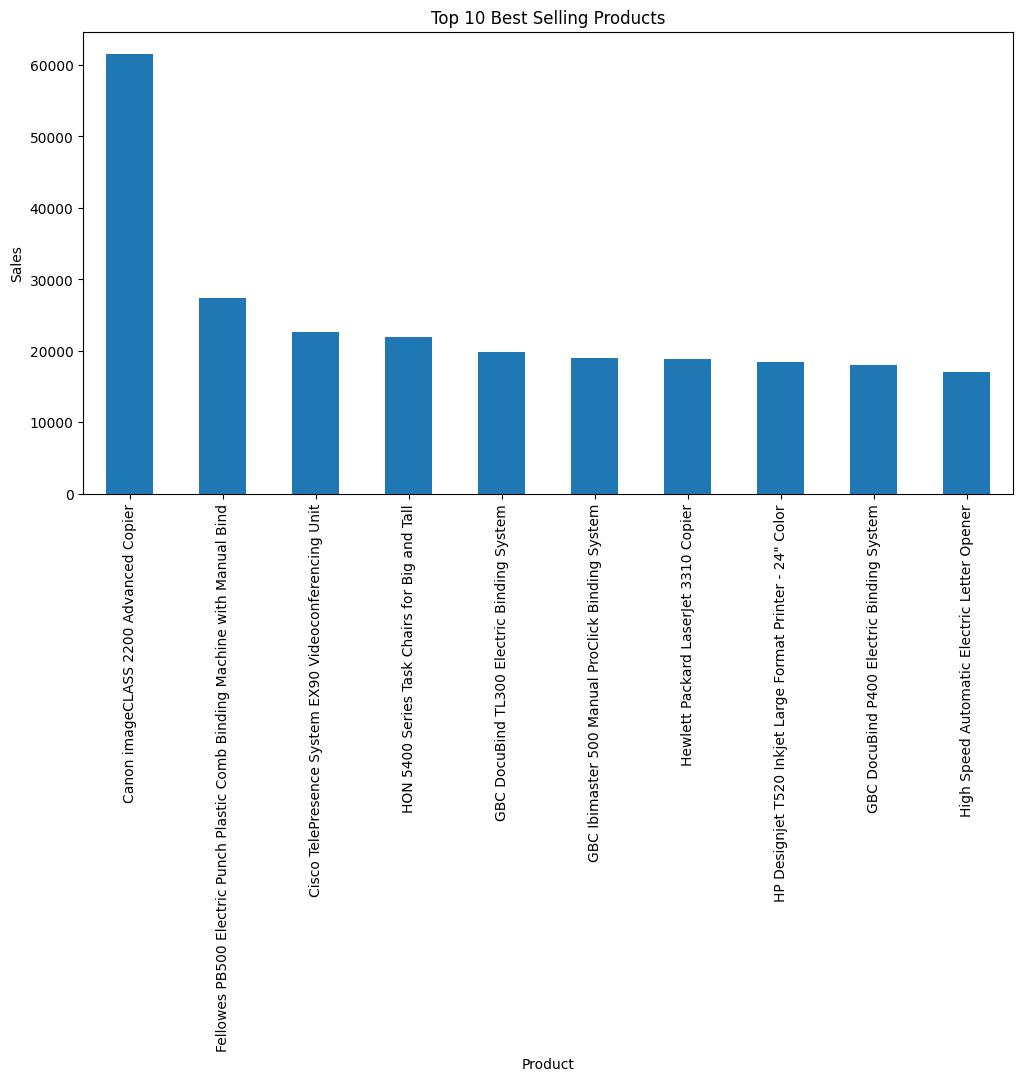

In [116]:
top_products = df.groupby('Product Name')['Sales'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(12,6))
top_products.plot(kind='bar')

plt.title("Top 10 Best Selling Products")
plt.xlabel("Product")
plt.ylabel("Sales")

plt.show()

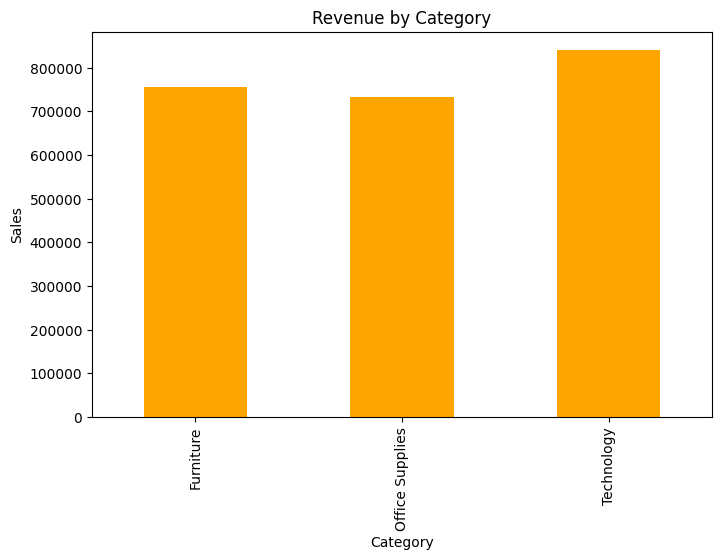

In [117]:
category_sales = df.groupby('Category')['Sales'].sum()

plt.figure(figsize=(8,5))
category_sales.plot(kind='bar', color='orange')

plt.title("Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Sales")

plt.show()

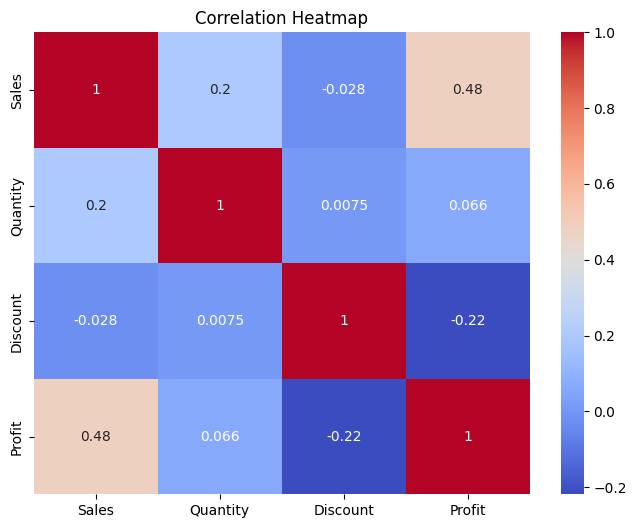

In [118]:
plt.figure(figsize=(8,6))

sns.heatmap(
    df[['Sales','Quantity','Discount','Profit']].corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()

Observation:
Sales and Profit show a positive relationship, while excessive discounts can negatively impact profit.

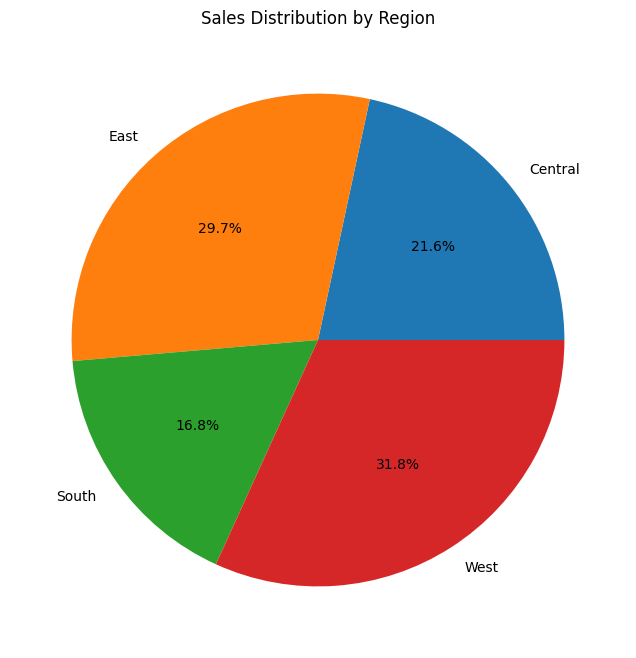

In [119]:
region_sales = df.groupby('Region')['Sales'].sum()

plt.figure(figsize=(8,8))

region_sales.plot(
    kind='pie',
    autopct='%1.1f%%'
)

plt.title("Sales Distribution by Region")
plt.ylabel("")

plt.show()

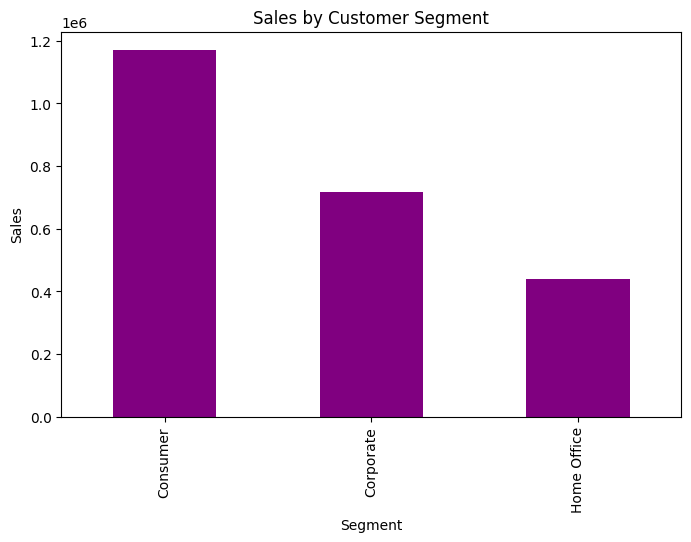

In [120]:
segment_sales = df.groupby('Segment')['Sales'].sum()

plt.figure(figsize=(8,5))

segment_sales.plot(
    kind='bar',
    color='purple'
)

plt.title("Sales by Customer Segment")
plt.xlabel("Segment")
plt.ylabel("Sales")

plt.show()


Conclusion and Business Recommendations

1. Technology is the highest revenue-generating category and should receive increased focus in marketing and inventory planning.
2. Quarterly sales trends indicate seasonal patterns, making demand forecasting essential for stock optimization.
3. Regional sales performance varies significantly, suggesting the need for region-specific marketing strategies.
4. Excessive discounts may reduce profitability, so discount policies should be reviewed regularly.
5. High-value customer segments should be targeted through loyalty programs and personalized promotions to increase repeat purchases.
